# 04 — Calibration de River HalfSpaceTrees (détection de fuites en ligne)

**Objectif** : choisir les hyperparamètres (`n_trees`, `height`, `window_size`), le **seuil de score** et le nombre de **messages consécutifs** au-dessus du seuil du détecteur en ligne utilisé par le consumer MQTT. Pour cela, on rejoue en flux un jeu **synthétique** au format du simulateur : débits des tronçons S1–S5, avec des fuites injectées.

| | |
|---|---|
| **Entrées** | aucune : le flux est généré ici (graine fixe), au même format que `simulator/publisher.py` |
| **Sorties** | `models/artifacts/river_config.json` (hyperparamètres + seuil + mise à l'échelle), `river_metrics.json` ; expérience MLflow `04_river_calibration` |
| **Durée** | ~2–5 min (27 combinaisons rejouées sur un flux de 14 jours, puis un flux de test, un flux avec dérive, et 5 graines × 2 scénarios pour la règle adaptative) |

River **apprend en ligne** (`score_one` puis `learn_one` à chaque message). Rien n'est exporté d'autre que la configuration : le consumer recrée le modèle à partir de `river_config.json`.

> ⚠️ Toutes les données de ce notebook sont **simulées** (estimation simulée) : la topologie, les débits et les fuites reprennent le comportement prévu du simulateur, pas des mesures réelles.

## 1. Imports, chemins et MLflow

In [14]:
import json
import logging
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import seaborn as sns
import itertools

import river
from river import anomaly

EXPERIMENT = "04_river_calibration"
SEED = 42
np.random.seed(SEED)

# Racine du projet : fonctionne que le notebook soit lancé depuis notebooks/ ou depuis la racine
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "aquamind_core").is_dir())
sys.path.insert(0, str(ROOT))
PROCESSED = ROOT / "data" / "processed"
ARTIFACTS = ROOT / "models" / "artifacts"
ARTIFACTS.mkdir(parents=True, exist_ok=True)

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(message)s")
logging.getLogger("mlflow").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

# MLflow : file store local mlruns/ à la racine (équivalent de "file:../mlruns" depuis notebooks/)
mlflow.set_tracking_uri((ROOT / "mlruns").as_uri())
mlflow.set_experiment(EXPERIMENT)
mlflow.end_run()  # ferme un run resté ouvert par une exécution précédente interrompue
run = mlflow.start_run(run_name=f"{EXPERIMENT}-{time.strftime('%Y%m%d-%H%M%S')}")
T0 = time.perf_counter()
print("Racine :", ROOT)
print("MLflow :", mlflow.get_tracking_uri(), "| run", run.info.run_id)

Racine : c:\Users\ghodh\aquamind
MLflow : file:///c:/Users/ghodh/aquamind/mlruns | run 4c27cc31cd424d86a6ee9f0fa2cc53e6


## 2. Flux synthétique au format du simulateur

**Topologie** : S1 = conduite principale (sortie de pompe) ; S2, S3, S4 = parcelles A, B, C ; S5 = retour vers le réservoir. Hors fuite, S1 = S2 + S3 + S4 + S5.

- **Horloge** : 1 message toutes les **10 min simulées** (6 messages/heure). Avec `SIM_SECONDS_PER_HOUR=5`, cela fait 1 message toutes les 0,83 s réelles.
- **Plan** : irrigation solaire de 7h à 18h, rotation aléatoire de 1 à 2 parcelles par heure, 3 à 7,4 m³/h ; environ 15 % des heures sans pompage ; retour réservoir de 8 %.
- **Dérive** (section 6 bis seulement) : à partir du jour 7, un **rinçage automatique des filtres** du goutte-à-goutte consomme 0,6 m³/h pendant l'irrigation. Ce prélèvement est légitime, mais il passe par S1 sans passer par S2–S4. Ce n'est **pas** une fuite : toute alerte qu'il provoque est une fausse alerte.
- **Mesures** : plan + rampe d'un message à chaque changement de consigne + bruit (2 % relatif, 0,05 m³/h absolu) + **pics isolés** sur un capteur (probabilité 0,2 %), qui servent de pièges à fausses alertes.
- **Fuites** : sur un tronçon S2–S4, entre le compteur S1 et le compteur du tronçon, de 0,4 à 3 m³/h, pendant 1 à 6 h. Le débit S1 augmente du débit de fuite, le tronçon reçoit 25 % de ce débit en moins, et **le bilan de masse est rompu**. Une fuite n'est observable que pendant le pompage : l'étiquette vaut donc 1 si la fuite est active **et** la pompe en marche.

In [15]:
TICK_MIN = 10
TICKS_PER_H = 60 // TICK_MIN
SIM_SECONDS_PER_HOUR = 5          # valeur de .env, pour convertir les délais en secondes réelles
PLOTS = {"A": "S2", "B": "S3", "C": "S4"}
SECTIONS = ["S1", "S2", "S3", "S4", "S5"]
PUMP_MAX = 8.0                    # m³/h (farm.json)
RETURN_FRAC = 0.08
NOISE_REL, NOISE_ABS = 0.02, 0.05
SPIKE_PROB, SPIKE_SIZE = 0.002, 1.5
WARMUP_DAYS = 3                   # pas de fuite ni d'évaluation pendant le préchauffage
WARMUP = WARMUP_DAYS * 24 * TICKS_PER_H


def make_stream(days: int, n_leaks: int, seed: int, drift_day: int | None = None,
                flush_m3h: float = 0.6) -> pd.DataFrame:
    """Flux synthétique S1–S5 (mesures + plan) avec fuites injectées. Une ligne = un message.

    drift_day : à partir de ce jour, rinçage des filtres (flush_m3h) mesuré par S1 mais pas par S2–S4
    pendant le pompage (dérive légitime, pas une fuite). N'ajoute aucun tirage aléatoire."""
    rng = np.random.default_rng(seed)
    n = days * 24 * TICKS_PER_H
    hour_of_tick = np.arange(n) // TICKS_PER_H

    plan_h = {p: np.zeros(days * 24) for p in PLOTS}
    for d in range(days):
        for h in range(7, 18):
            if rng.random() < 0.15:
                continue
            k = int(rng.integers(1, 3))
            active = rng.choice(list(PLOTS), size=k, replace=False)
            total = rng.uniform(3.0, PUMP_MAX * (1 - RETURN_FRAC))
            for p in active:
                plan_h[p][d * 24 + h] = total / k
    plan = {PLOTS[p]: plan_h[p][hour_of_tick] for p in PLOTS}
    delivered = plan["S2"] + plan["S3"] + plan["S4"]
    plan["S5"] = RETURN_FRAC / (1 - RETURN_FRAC) * delivered
    plan["S1"] = delivered + plan["S5"]

    meas = {}
    for s in SECTIONS:
        p = plan[s]
        prev = np.r_[p[0], p[:-1]]
        actual = np.where(p != prev, 0.5 * (p + prev), p)  # la conduite met un message à se stabiliser
        meas[s] = actual * (1 + NOISE_REL * rng.standard_normal(n)) + NOISE_ABS * rng.standard_normal(n)

    pumping = plan["S1"] > 0.5
    leak_rate = np.zeros(n)
    leak_section = np.full(n, "", dtype=object)
    candidates = np.flatnonzero(pumping[WARMUP:]) + WARMUP
    for st in np.sort(rng.choice(candidates, size=n_leaks, replace=False)):
        dur = int(rng.integers(6, 37))
        sl = slice(st, min(st + dur, n))
        leak_rate[sl] = rng.uniform(0.4, 3.0)
        leak_section[sl] = rng.choice(["S2", "S3", "S4"])
    active = (leak_rate > 0) & pumping
    meas["S1"] = meas["S1"] + np.where(active, leak_rate, 0.0)
    for s in ["S2", "S3", "S4"]:
        meas[s] = meas[s] - np.where(active & (leak_section == s), 0.25 * leak_rate, 0.0)
    drift = np.zeros(n, dtype=bool)
    if drift_day is not None:
        drift = (np.arange(n) >= drift_day * 24 * TICKS_PER_H) & pumping
        meas["S1"] = meas["S1"] + np.where(drift, flush_m3h, 0.0)

    spikes = rng.random(n) < SPIKE_PROB
    spike_section = rng.choice(SECTIONS, size=n)
    spike_sign = rng.choice([-1.0, 1.0], size=n)
    for s in SECTIONS:
        meas[s] = np.clip(meas[s] + np.where(spikes & (spike_section == s), SPIKE_SIZE * spike_sign, 0.0), 0, None)

    ts = pd.date_range("2026-06-01", periods=n, freq=f"{TICK_MIN}min")
    df = pd.DataFrame({**{f"{s}_flow": meas[s] for s in SECTIONS}, **{f"{s}_plan": plan[s] for s in SECTIONS}},
                      index=ts)
    df["leak_rate"] = np.where(active, leak_rate, 0.0)
    df["leak_section"] = np.where(active, leak_section, "")
    df["label"] = active.astype(int)
    df["spike"] = spikes.astype(int)
    df["drift"] = drift.astype(int)
    return df


val_df = make_stream(days=14, n_leaks=14, seed=SEED)        # calibration
test_df = make_stream(days=14, n_leaks=14, seed=SEED + 1)   # évaluation finale (autre graine)
for name, d in [("validation", val_df), ("test", test_df)]:
    print(f"{name:10s} : {len(d)} messages, {d['label'].mean() * 100:.1f} % en fuite, {int(d['spike'].sum())} pics isolés")
val_df.head()

validation : 2016 messages, 8.1 % en fuite, 8 pics isolés
test       : 2016 messages, 8.7 % en fuite, 0 pics isolés


,S1_flow,S2_flow,S3_flow,S4_flow,S5_flow,S1_plan,S2_plan,S3_plan,S4_plan,S5_plan,leak_rate,leak_section,label,spike,drift
2026-06-01 00:00:00,0.010872,0.000000,0.051509,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,,0,0,0
2026-06-01 00:10:00,0.000000,0.000000,0.036513,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,,0,0,0
2026-06-01 00:20:00,0.000000,0.000000,0.000000,0.000000,0.007143,0.0,0.0,0.0,0.0,0.0,0.0,,0,0,0
2026-06-01 00:30:00,0.000000,0.000000,0.000000,0.032399,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,,0,0,0
2026-06-01 00:40:00,0.005355,0.020721,0.000000,0.013973,0.038098,0.0,0.0,0.0,0.0,0.0,0.0,,0,0,0


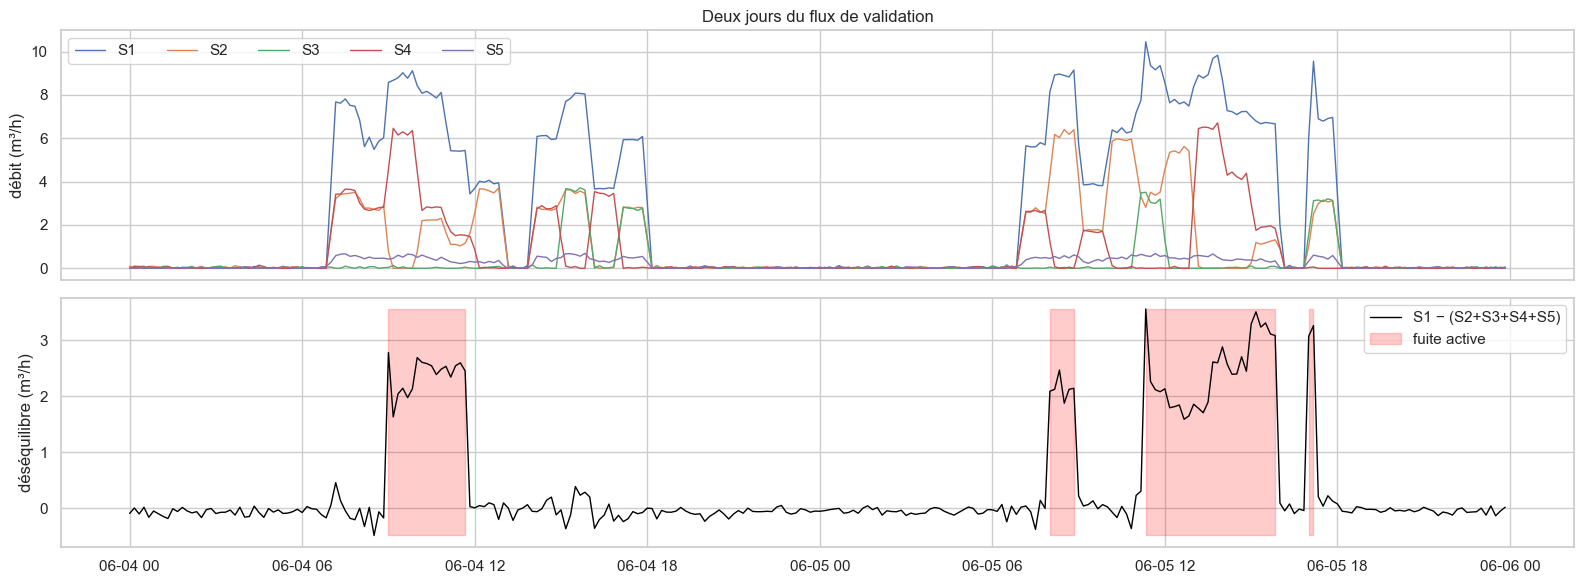

In [16]:
day = val_df.iloc[WARMUP:WARMUP + 2 * 24 * TICKS_PER_H]
fig, axes = plt.subplots(2, 1, figsize=(16, 6), sharex=True)
for s in SECTIONS:
    axes[0].plot(day.index, day[f"{s}_flow"], lw=1, label=s)
axes[0].set_ylabel("débit (m³/h)")
axes[0].legend(ncol=5)
axes[0].set_title("Deux jours du flux de validation")
imb = day["S1_flow"] - day[["S2_flow", "S3_flow", "S4_flow", "S5_flow"]].sum(axis=1)
axes[1].plot(day.index, imb, color="black", lw=1, label="S1 − (S2+S3+S4+S5)")
axes[1].fill_between(day.index, imb.min(), imb.max(), where=day["label"].astype(bool), color="red", alpha=0.2,
                     label="fuite active")
axes[1].set_ylabel("déséquilibre (m³/h)")
axes[1].legend()
fig.tight_layout()
mlflow.log_figure(fig, "fig_flux_synthetique.png")
plt.show()

## 3. Variables calculées par le consumer à chaque message

- `imbalance` = S1 − (S2 + S3 + S4 + S5) : rupture du bilan de masse.
- `s1_resid`, `s2_resid`, `s3_resid`, `s4_resid` = mesure − plan.

HalfSpaceTrees attend des valeurs dans [0, 1]. On applique une **mise à l'échelle fixe et physique**, `x01 = clip(0.5 + x / (2 × 4 m³/h), 0, 1)`, plutôt qu'un MinMaxScaler en ligne, instable au démarrage. Le consumer applique exactement la même formule (paramètre `scale_m3h` dans la config).

In [17]:
FEATURES = ["imbalance", "s1_resid", "s2_resid", "s3_resid", "s4_resid"]
SCALE_M3H = 4.0


def stream_features(df: pd.DataFrame) -> pd.DataFrame:
    f = pd.DataFrame(index=df.index)
    f["imbalance"] = df["S1_flow"] - df[["S2_flow", "S3_flow", "S4_flow", "S5_flow"]].sum(axis=1)
    f["s1_resid"] = df["S1_flow"] - df["S1_plan"]
    for s in ["S2", "S3", "S4"]:
        f[f"{s.lower()}_resid"] = df[f"{s}_flow"] - df[f"{s}_plan"]
    return f[FEATURES]


def to_unit(f: pd.DataFrame) -> pd.DataFrame:
    return (0.5 + f / (2 * SCALE_M3H)).clip(0.0, 1.0)


val_records = to_unit(stream_features(val_df)).to_dict("records")
test_records = to_unit(stream_features(test_df)).to_dict("records")
val_label = val_df["label"].to_numpy()
test_label = test_df["label"].to_numpy()
to_unit(stream_features(val_df)).describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
imbalance,2016.0,0.513,0.074,0.291,0.487,0.495,0.503,1.000
s1_resid,2016.0,0.518,0.091,0.023,0.500,0.501,0.508,1.000
s2_resid,2016.0,0.500,0.052,0.063,0.500,0.500,0.504,0.894
s3_resid,2016.0,0.502,0.046,0.080,0.500,0.500,0.504,0.919
s4_resid,2016.0,0.502,0.046,0.069,0.500,0.500,0.505,0.936


## 4. Rejeu en flux, alarmes et métriques

In [18]:
def hst_scores(records: list[dict], n_trees: int, height: int, window_size: int) -> np.ndarray:
    """Rejoue le flux : score_one puis learn_one à chaque message (comme le consumer)."""
    model = anomaly.HalfSpaceTrees(n_trees=n_trees, height=height, window_size=window_size, seed=SEED)
    out = np.empty(len(records))
    for i, x in enumerate(records):
        out[i] = model.score_one(x)
        model.learn_one(x)
    return out


def alarms(scores: np.ndarray, threshold: float, n_consec: int) -> np.ndarray:
    """Alarme si le score dépasse le seuil pendant n_consec messages consécutifs (anti-bruit)."""
    above = (scores > threshold).astype(int)
    run = np.convolve(above, np.ones(n_consec, dtype=int), mode="full")[: len(above)]
    return run >= n_consec


def events_of(label: np.ndarray) -> list[tuple[int, int]]:
    d = np.diff(np.r_[0, label.astype(int), 0])
    return list(zip(np.flatnonzero(d == 1), np.flatnonzero(d == -1)))  # [début, fin)


def evaluate(label: np.ndarray, alarm: np.ndarray, n_consec: int, start: int = WARMUP,
             end: int | None = None) -> dict:
    """Métriques sur les messages [start, end) : point par point, par événement, fausses alertes/jour."""
    end = len(label) if end is None else end
    y, a = label[start:end].astype(bool), alarm[start:end]
    tp, fp, fn = int((y & a).sum()), int((~y & a).sum()), int((y & ~a).sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    delays, detected = [], 0
    evs = [(s, e) for s, e in events_of(label) if start <= s < end]
    for s, e in evs:
        hit = np.flatnonzero(alarm[s:e + n_consec])
        if hit.size:
            detected += 1
            delays.append(int(hit[0]))
    # fausses alertes = alarmes qui démarrent hors fuite (fronts montants)
    rising = a & ~np.r_[False, a[:-1]]
    in_leak = np.zeros_like(y)
    for s, e in evs:
        in_leak[s - start:e - start + n_consec] = True
    false_alarms = int((rising & ~in_leak).sum())
    days = len(y) / (24 * TICKS_PER_H)
    return {"precision": precision, "recall": recall, "f1": f1, "events": len(evs), "detected": detected,
            "delay_msgs_mean": float(np.mean(delays)) if delays else float("nan"),
            "false_alarms_per_day": false_alarms / days}

## 5. Recherche sur grille (27 combinaisons) : seuil et messages consécutifs choisis sur la validation

In [19]:
GRID = {"n_trees": [10, 25, 50], "height": [6, 8, 10], "window_size": [72, 144, 288]}  # fenêtres : 12 h, 1 j, 2 j
N_CONSEC = [2, 3]
QUANTILES = np.linspace(0.80, 0.995, 80)

results = []
t_grid = time.perf_counter()
for n_trees, height, window_size in itertools.product(*GRID.values()):
    t = time.perf_counter()
    sc = hst_scores(val_records, n_trees, height, window_size)
    best = None
    for thr in np.unique(np.quantile(sc[WARMUP:], QUANTILES)):
        for n in N_CONSEC:
            m = evaluate(val_label, alarms(sc, thr, n), n)
            key = (round(m["f1"], 4), -np.nan_to_num(m["delay_msgs_mean"], nan=1e9))
            if best is None or key > best[0]:
                best = (key, float(thr), n, m)
    _, thr, n, m = best
    results.append({"n_trees": n_trees, "height": height, "window_size": window_size,
                    "threshold": thr, "n_consec": n, **m, "replay_s": time.perf_counter() - t})
results = pd.DataFrame(results).sort_values(["f1", "delay_msgs_mean"], ascending=[False, True])
print(f"Grille rejouée en {time.perf_counter() - t_grid:.0f} s")
for i, r in enumerate(results.itertuples()):
    mlflow.log_metric("grid_val_f1", r.f1, step=i)
results.head(10).round(3)

Grille rejouée en 22 s


,n_trees,height,window_size,threshold,n_consec,precision,recall,f1,events,detected,delay_msgs_mean,false_alarms_per_day,replay_s
17,25,10,288,0.332,2,0.890,0.933,0.911,16,16,0.688,0.545,0.859
26,50,10,288,0.340,2,0.899,0.921,0.910,16,16,0.688,0.364,1.811
11,25,6,288,0.243,2,0.888,0.921,0.904,16,16,0.812,0.545,0.315
20,50,6,288,0.227,2,0.883,0.921,0.901,16,16,0.812,0.636,0.715
23,50,8,288,0.328,2,0.912,0.884,0.898,16,16,0.812,0.091,1.040
14,25,8,288,0.298,2,0.887,0.909,0.898,16,16,0.812,0.545,0.491
8,10,10,288,0.356,2,0.864,0.933,0.897,16,16,0.688,1.000,0.450
16,25,10,144,0.390,2,0.897,0.848,0.871,16,16,0.938,0.273,1.244
10,25,6,144,0.289,2,0.886,0.854,0.870,16,16,0.875,0.455,0.344
7,10,10,144,0.406,2,0.876,0.860,0.868,16,16,0.812,0.545,0.457


INFO Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO Using categorical un

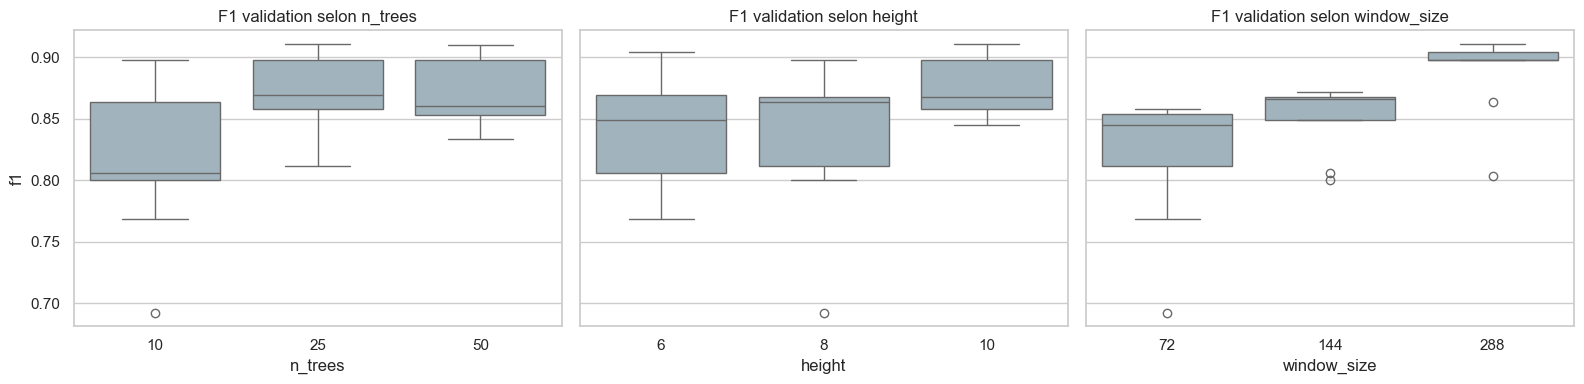

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, (param, values) in zip(axes, GRID.items()):
    sns.boxplot(data=results, x=param, y="f1", ax=ax, color="#9db4c0")
    ax.set_title(f"F1 validation selon {param}")
fig.tight_layout()
mlflow.log_figure(fig, "fig_grid.png")
plt.show()

## 6. Évaluation finale sur un flux de test indépendant (autre graine) et comparaison à une règle simple

In [21]:
BEST = results.iloc[0]
PARAMS = {"n_trees": int(BEST["n_trees"]), "height": int(BEST["height"]), "window_size": int(BEST["window_size"])}
THRESHOLD, N_CONSEC_BEST = float(BEST["threshold"]), int(BEST["n_consec"])
print("Retenu :", PARAMS, f"| seuil {THRESHOLD:.4f} | {N_CONSEC_BEST} messages consécutifs")

test_scores = hst_scores(test_records, **PARAMS)
test_alarm = alarms(test_scores, THRESHOLD, N_CONSEC_BEST)
hst_test = evaluate(test_label, test_alarm, N_CONSEC_BEST)

# Référence : règle fixe sur le bilan de masse |déséquilibre| > 0,5 m³/h pendant N messages
RULE_THRESHOLD = 0.5  # m³/h
imb_test = stream_features(test_df)["imbalance"].abs().to_numpy()
rule_test_alarm = alarms(imb_test, RULE_THRESHOLD, N_CONSEC_BEST)
rule_test = evaluate(test_label, rule_test_alarm, N_CONSEC_BEST)
hybrid_test = evaluate(test_label, rule_test_alarm & test_alarm, N_CONSEC_BEST)

msg_seconds = SIM_SECONDS_PER_HOUR / TICKS_PER_H
comparison = pd.DataFrame({"HalfSpaceTrees": hst_test, "Règle |déséquilibre| > 0,5": rule_test,
                           "Hybride (règle ET River)": hybrid_test}).T
comparison["délai moyen (s réelles)"] = comparison["delay_msgs_mean"] * msg_seconds
comparison["délai moyen (min simulées)"] = comparison["delay_msgs_mean"] * TICK_MIN
comparison.round(3)

Retenu : {'n_trees': 25, 'height': 10, 'window_size': 288} | seuil 0.3317 | 2 messages consécutifs


,precision,recall,f1,events,detected,delay_msgs_mean,false_alarms_per_day,délai moyen (s réelles),délai moyen (min simulées)
HalfSpaceTrees,0.884,0.954,0.918,12.0,12.0,0.667,0.909,0.556,6.667
"Règle |déséquilibre| > 0,5",1.000,0.857,0.923,12.0,12.0,1.000,0.000,0.833,10.000
Hybride (règle ET River),1.000,0.857,0.923,12.0,12.0,1.000,0.000,0.833,10.000


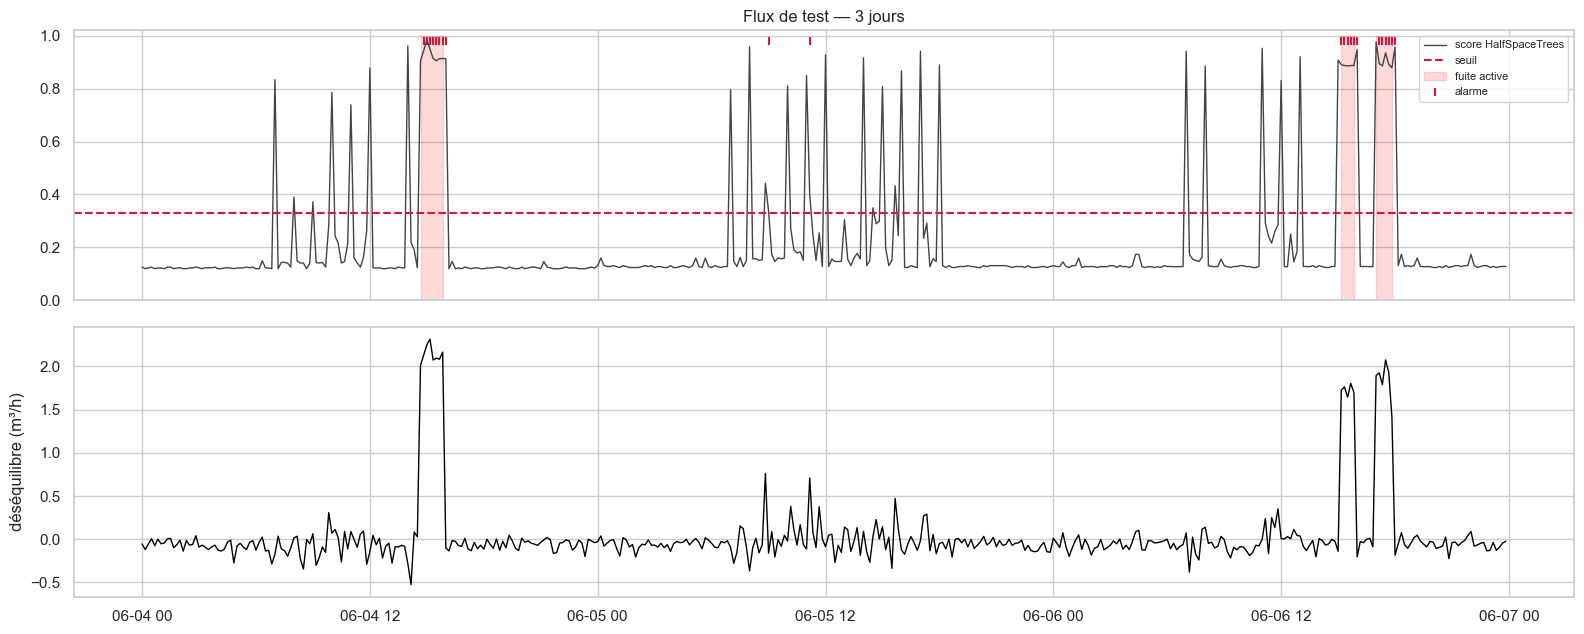

In [22]:
seg = slice(WARMUP, WARMUP + 3 * 24 * TICKS_PER_H)
d = test_df.iloc[seg]
fig, axes = plt.subplots(2, 1, figsize=(16, 6.5), sharex=True)
axes[0].plot(d.index, test_scores[seg], color="#444", lw=1, label="score HalfSpaceTrees")
axes[0].axhline(THRESHOLD, color="crimson", ls="--", label="seuil")
axes[0].fill_between(d.index, 0, 1, where=d["label"].astype(bool), color="red", alpha=0.15, label="fuite active")
axes[0].scatter(d.index[test_alarm[seg]], np.full(int(test_alarm[seg].sum()), 0.98), marker="|", color="crimson",
                label="alarme")
axes[0].set_ylim(0, 1.02)
axes[0].legend(loc="upper right", fontsize=8)
axes[0].set_title("Flux de test — 3 jours")
axes[1].plot(d.index, stream_features(d)["imbalance"], color="black", lw=1)
axes[1].set_ylabel("déséquilibre (m³/h)")
fig.tight_layout()
mlflow.log_figure(fig, "fig_test_stream.png")
plt.show()

## 6 bis. Scénario de dérive : un changement de plan légitime

Une règle à seuil fixe ne connaît que le réseau « d'origine ». Au jour 7, on ajoute un **rinçage automatique des filtres** (0,6 m³/h pendant l'irrigation) : le déséquilibre S1 − (S2+S3+S4+S5) passe durablement à environ 0,6 m³/h **sans aucune fuite**.

- La **règle** (|déséquilibre| > 0,5 m³/h) va déclencher à chaque créneau d'irrigation : ce sont des fausses alertes.
- **River** apprend en continu (`learn_one`) : après environ une fenêtre (`window_size` messages), ce nouveau régime devient « normal » pour lui. Il doit continuer à détecter les fuites qui s'ajoutent au rinçage.
- **Hybride** : on n'alerte que si la règle **et** River sont d'accord.

Tout est rejoué avec la configuration et les seuils **déjà choisis** (aucun recalage sur ce flux). Le flux a une graine différente (44) ; il est généré et évalué de la même façon que précédemment.

In [23]:
DRIFT_DAY = 7
FLUSH_M3H = 0.6
drift_df = make_stream(days=14, n_leaks=14, seed=SEED + 2, drift_day=DRIFT_DAY, flush_m3h=FLUSH_M3H)
drift_label = drift_df["label"].to_numpy()
drift_scores = hst_scores(to_unit(stream_features(drift_df)).to_dict("records"), **PARAMS)
drift_imb = stream_features(drift_df)["imbalance"].abs().to_numpy()

drift_alarms = {"HalfSpaceTrees": alarms(drift_scores, THRESHOLD, N_CONSEC_BEST),
                "Règle |déséquilibre| > 0,5": alarms(drift_imb, RULE_THRESHOLD, N_CONSEC_BEST)}
drift_alarms["Hybride (règle ET River)"] = drift_alarms["HalfSpaceTrees"] & drift_alarms["Règle |déséquilibre| > 0,5"]

DRIFT_START = DRIFT_DAY * 24 * TICKS_PER_H
ADAPT = PARAMS["window_size"]  # temps d'adaptation attendu de River (une fenêtre)
PHASES = {"avant la dérive": (WARMUP, DRIFT_START),
          "après la dérive (tout)": (DRIFT_START, len(drift_df)),
          f"après adaptation (+{ADAPT} messages)": (DRIFT_START + ADAPT, len(drift_df))}
rows = []
for method, al in drift_alarms.items():
    for phase, (a, b) in PHASES.items():
        m = evaluate(drift_label, al, N_CONSEC_BEST, start=a, end=b)
        rows.append({"méthode": method, "phase": phase, "F1": m["f1"], "précision": m["precision"],
                     "rappel": m["recall"], "fuites détectées": f"{m['detected']}/{m['events']}",
                     "délai moyen (messages)": m["delay_msgs_mean"],
                     "fausses alertes / jour": m["false_alarms_per_day"]})
drift_table = pd.DataFrame(rows).set_index(["méthode", "phase"])
display(drift_table.round(3))

after = "après la dérive (tout)"
fa = {k: drift_table.loc[(k, after), "fausses alertes / jour"] for k in drift_alarms}
f1 = {k: drift_table.loc[(k, after), "F1"] for k in drift_alarms}
RIVER_BETTER = (f1["HalfSpaceTrees"] >= f1["Règle |déséquilibre| > 0,5"]
                and fa["HalfSpaceTrees"] < fa["Règle |déséquilibre| > 0,5"])
best_mode = max(f1, key=lambda k: (round(f1[k], 3), -fa[k]))
RECOMMENDED_MODE = {"HalfSpaceTrees": "river", "Règle |déséquilibre| > 0,5": "rule",
                    "Hybride (règle ET River)": "hybrid_and"}[best_mode]
print(f"Après la dérive : F1 règle {f1['Règle |déséquilibre| > 0,5']:.3f} ({fa['Règle |déséquilibre| > 0,5']:.1f} FA/j) | "
      f"River {f1['HalfSpaceTrees']:.3f} ({fa['HalfSpaceTrees']:.1f} FA/j) | "
      f"hybride {f1['Hybride (règle ET River)']:.3f} ({fa['Hybride (règle ET River)']:.1f} FA/j)")
if RIVER_BETTER:
    print("→ Sous dérive, River fait mieux que la règle fixe (moins de fausses alertes, F1 au moins égal).")
else:
    print("→ Même sous dérive, River NE fait PAS mieux que la règle fixe : on garde l'hybride règle + River.")
print(f"Mode recommandé pour le consumer (meilleur F1 après la dérive) : {best_mode} → '{RECOMMENDED_MODE}'")
mlflow.log_metrics({f"drift_f1_{k2}": float(f1[k]) for k, k2 in
                    zip(drift_alarms, ["river", "rule", "hybrid"])})
mlflow.log_metrics({f"drift_fa_day_{k2}": float(fa[k]) for k, k2 in
                    zip(drift_alarms, ["river", "rule", "hybrid"])})

F1  précision  \
méthode                    phase                                                
HalfSpaceTrees             avant la dérive                   0.950      0.957   
                           après la dérive (tout)            0.475      0.314   
                           après adaptation (+288 messages)  0.563      0.396   
Règle |déséquilibre| > 0,5 avant la dérive                   0.964      1.000   
                           après la dérive (tout)            0.618      0.459   
                           après adaptation (+288 messages)  0.677      0.524   
Hybride (règle ET River)   avant la dérive                   0.964      1.000   
                           après la dérive (tout)            0.631      0.473   
                           après adaptation (+288 messages)  0.693      0.544   

                                                             rappel  \
méthode                    phase                                      
HalfSpaceTrees             avant la dérive                    0.944   
                           après la dérive (tout)             0.979   
                           après adaptation (+288 messages)   0.978   
Règle |déséquilibre| > 0,5 avant la dérive                    0.930   
                           après la dérive (tout)             0.947   
                           après adaptation (+288 messages)   0.956   
Hybride (règle ET River)   avant la dérive                    0.930   
                           après la dérive (tout)             0.947   
                           après adaptation (+288 messages)   0.956   

                                                            fuites détectées  \
méthode                    phase                                               
HalfSpaceTrees             avant la dérive                               5/5   
                           après la dérive (tout)                        6/6   
                           après adaptation (+288 messages)              5/5   
Règle |déséquilibre| > 0,5 avant la dérive                               5/5   
                           après la dérive (tout)                        6/6   
                           après adaptation (+288 messages)              5/5   
Hybride (règle ET River)   avant la dérive                               5/5   
                           après la dérive (tout)                        6/6   
                           après adaptation (+288 messages)              5/5   

                                                             délai moyen (messages)  \
méthode                    phase                                                      
HalfSpaceTrees             avant la dérive                                    0.800   
                           après la dérive (tout)                             0.333   
                           après adaptation (+288 messages)                   0.400   
Règle |déséquilibre| > 0,5 avant la dérive                                    1.000   
                           après la dérive (tout)                             0.833   
                           après adaptation (+288 messages)                   0.800   
Hybride (règle ET River)   avant la dérive                                    1.000   
                           après la dérive (tout)                             0.833   
                           après adaptation (+288 messages)                   0.800   

                                                             fausses alertes / jour  
méthode                    phase                                                     
HalfSpaceTrees             avant la dérive                                    0.000  
                           après la dérive (tout)                             4.429  
                           après adaptation (+288 messages)                   4.200  
Règle |déséquilibre| > 0,5 avant la dérive                                    0.000  
                           après la

Après la dérive : F1 règle 0.618 (5.9 FA/j) | River 0.475 (4.4 FA/j) | hybride 0.631 (5.6 FA/j)
→ Même sous dérive, River NE fait PAS mieux que la règle fixe : on garde l'hybride règle + River.
Mode recommandé pour le consumer (meilleur F1 après la dérive) : Hybride (règle ET River) → 'hybrid_and'


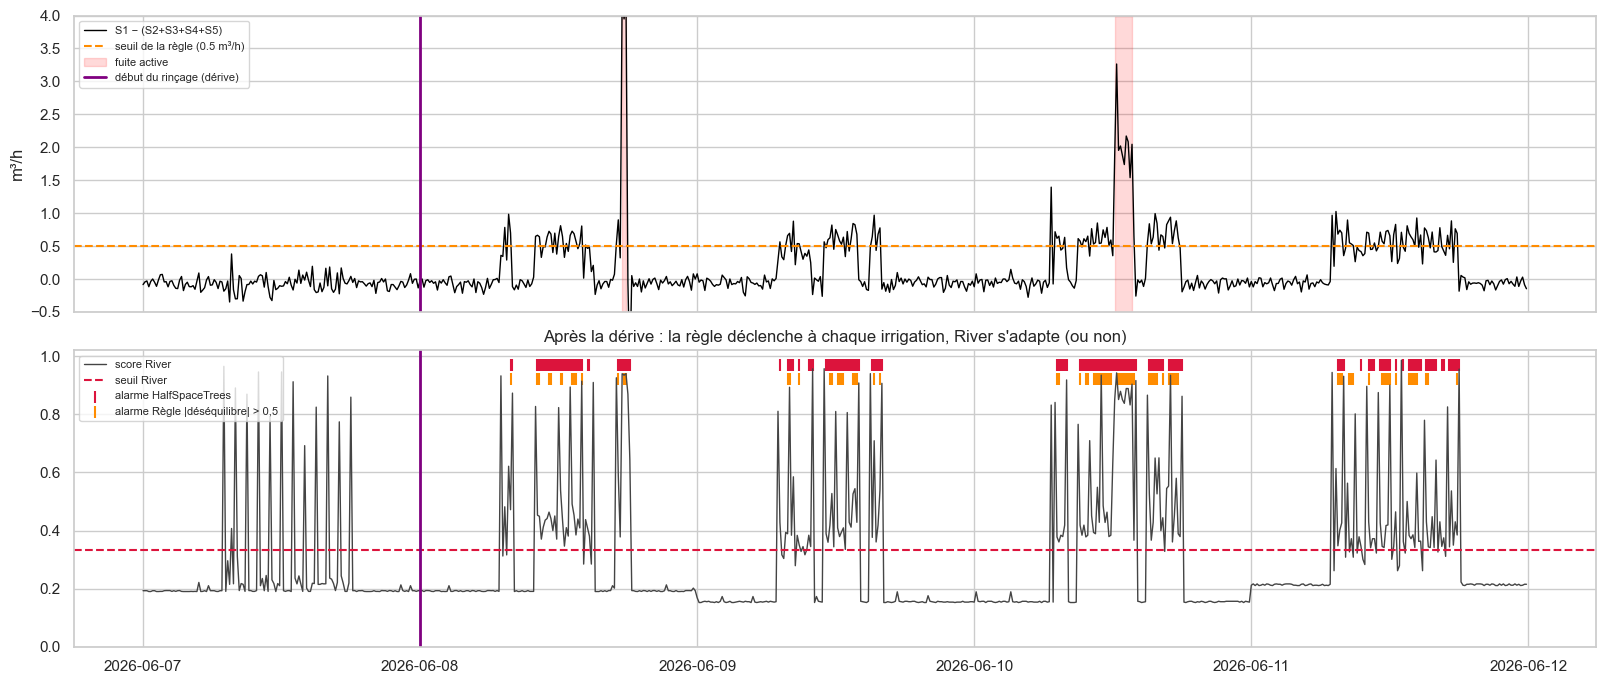

In [24]:
seg = slice(DRIFT_START - 24 * TICKS_PER_H, DRIFT_START + 4 * 24 * TICKS_PER_H)
d = drift_df.iloc[seg]
fig, axes = plt.subplots(2, 1, figsize=(16, 7), sharex=True)
axes[0].plot(d.index, stream_features(d)["imbalance"], color="black", lw=1, label="S1 − (S2+S3+S4+S5)")
axes[0].axhline(RULE_THRESHOLD, color="darkorange", ls="--", label=f"seuil de la règle ({RULE_THRESHOLD} m³/h)")
axes[0].fill_between(d.index, -0.5, 4, where=d["label"].astype(bool), color="red", alpha=0.15, label="fuite active")
axes[0].axvline(drift_df.index[DRIFT_START], color="purple", lw=2, label="début du rinçage (dérive)")
axes[0].set_ylim(-0.5, 4)
axes[0].set_ylabel("m³/h")
axes[0].legend(loc="upper left", fontsize=8)
axes[1].plot(d.index, drift_scores[seg], color="#444", lw=1, label="score River")
axes[1].axhline(THRESHOLD, color="crimson", ls="--", label="seuil River")
for (name, al), y, c in zip(list(drift_alarms.items())[:2], [0.97, 0.92], ["crimson", "darkorange"]):
    idx_al = d.index[al[seg]]
    axes[1].scatter(idx_al, np.full(len(idx_al), y), marker="|", color=c, s=80, label=f"alarme {name}")
axes[1].axvline(drift_df.index[DRIFT_START], color="purple", lw=2)
axes[1].set_ylim(0, 1.02)
axes[1].legend(loc="upper left", fontsize=8)
axes[1].set_title("Après la dérive : la règle déclenche à chaque irrigation, River s'adapte (ou non)")
fig.tight_layout()
mlflow.log_figure(fig, "fig_derive.png")
plt.show()

## 6 ter. Règle adaptative et robustesse sur 5 graines

La section 6 bis montre que la règle fixe **et** River déclenchent à tort après un changement légitime. On teste ici la **règle adaptative** prévue pour la Phase 5, puis on mesure tout sur **5 graines** au lieu d'une seule.

**Règle adaptative** (mêmes seuil et persistance que la règle fixe : 0,5 m³/h, `N_CONSEC_BEST` messages) :
- **Pendant le pompage** (`S1_plan > 0,5`), on compare le déséquilibre à une **référence** = médiane du déséquilibre sur les `ADAPT_WINDOW` derniers messages de pompage jugés normaux. Pompe à l'arrêt : référence 0 (le rinçage ne coule que pendant l'irrigation).
- **Gel pendant une suspicion** : un message au-dessus du seuil n'entre pas dans la référence. Sinon, une fuite deviendrait « normale » en quelques messages.
- **« Nouveau normal »** : si l'écart persiste pendant `ACCEPT_AFTER` messages de pompage (8 h, plus que la plus longue fuite simulée de 6 h), on l'accepte et la référence est reconstruite sur ces messages. Dans l'application, c'est le **bouton « nouveau normal »** ; ici, on simule l'agriculteur qui confirme au bout de 8 h de pompage.

Les paramètres sont **fixés à l'avance, sans recalage** sur les flux évalués. River garde la configuration choisie en section 5.

**Évaluation** : 5 flux normaux (graines 43 et 101 à 104) et 5 flux avec dérive au jour 7 (graines 44 et 201 à 204). On rapporte **moyenne ± écart-type** sur les 5 graines. Temps normal : après le préchauffage. Dérive : **tout ce qui suit le début du rinçage**, y compris le temps d'adaptation. Chaque flux a ses propres pics isolés, ce qui teste aussi la robustesse aux pics. Avec ~6 fuites après la dérive par flux, les écarts-types sont larges : ce sont des **estimations simulées**.

Flux de dérive (graine 44), après la dérive : règle adaptative 6/6 fuites, 0.86 fausses alertes/jour (règle fixe : 5.86)


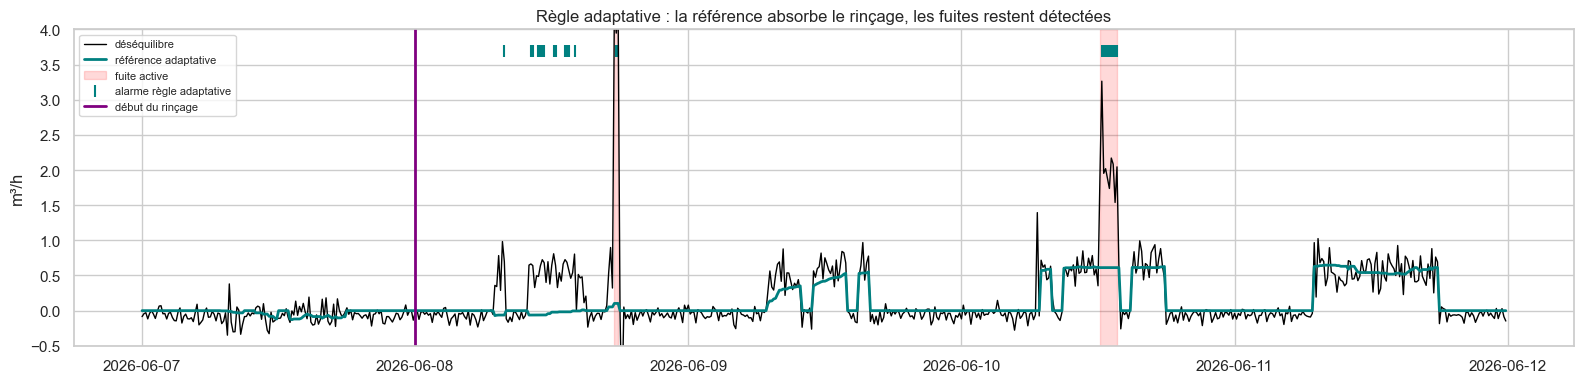

In [25]:
ADAPT_WINDOW = 36       # messages de pompage dans la référence (6 h de pompage)
ADAPT_MIN = 6           # en dessous, référence 0 (comme la règle fixe)
ACCEPT_AFTER = 48       # « nouveau normal » après 8 h de pompage en écart persistant (> plus longue fuite, 6 h)


def adaptive_rule(df: pd.DataFrame, threshold: float = RULE_THRESHOLD, n_consec: int = None,
                  window: int = ADAPT_WINDOW, accept_after: int = ACCEPT_AFTER) -> tuple[np.ndarray, np.ndarray]:
    """Règle adaptative, message par message comme le fera le consumer.

    Retourne (alarme, référence utilisée). Le consumer connaît le plan : pompage = S1_plan > 0,5."""
    n_consec = N_CONSEC_BEST if n_consec is None else n_consec
    imb = stream_features(df)["imbalance"].to_numpy()
    pump = df["S1_plan"].to_numpy() > 0.5
    hist: list[float] = []      # pompage jugé normal (fenêtre glissante)
    pending: list[float] = []   # pompage en écart, mis de côté tant que l'écart n'est pas accepté
    above_run = 0
    alarm = np.zeros(len(imb), dtype=bool)
    base_used = np.zeros(len(imb))
    for t in range(len(imb)):
        base = float(np.median(hist[-window:])) if pump[t] and len(hist) >= ADAPT_MIN else 0.0
        base_used[t] = base
        above_run = above_run + 1 if abs(imb[t] - base) > threshold else 0
        alarm[t] = above_run >= n_consec
        if not pump[t]:
            continue
        if above_run > 0:
            pending.append(imb[t])
            if len(pending) >= accept_after:      # nouveau normal : l'écart persistant devient la référence
                hist = pending[-window:]
                pending = []
                above_run = 0
        else:
            pending = []                          # écart bref (pic, fuite réparée) : oublié, pas appris
            hist.append(imb[t])
            hist = hist[-window:]
    return alarm, base_used


# Contrôle rapide sur le flux de dérive de la section 6 bis
adapt_drift_alarm, adapt_drift_base = adaptive_rule(drift_df)
m = evaluate(drift_label, adapt_drift_alarm, N_CONSEC_BEST, start=DRIFT_START)
print(f"Flux de dérive (graine {SEED + 2}), après la dérive : règle adaptative {m['detected']}/{m['events']} fuites, "
      f"{m['false_alarms_per_day']:.2f} fausses alertes/jour (règle fixe : {fa['Règle |déséquilibre| > 0,5']:.2f})")

seg = slice(DRIFT_START - 24 * TICKS_PER_H, DRIFT_START + 4 * 24 * TICKS_PER_H)
d = drift_df.iloc[seg]
fig, ax = plt.subplots(figsize=(16, 4))
ax.plot(d.index, stream_features(d)["imbalance"], color="black", lw=1, label="déséquilibre")
ax.plot(d.index, adapt_drift_base[seg], color="teal", lw=2, label="référence adaptative")
ax.fill_between(d.index, -0.5, 4, where=d["label"].astype(bool), color="red", alpha=0.15, label="fuite active")
idx_al = d.index[adapt_drift_alarm[seg]]
ax.scatter(idx_al, np.full(len(idx_al), 3.7), marker="|", color="teal", s=80, label="alarme règle adaptative")
ax.axvline(drift_df.index[DRIFT_START], color="purple", lw=2, label="début du rinçage")
ax.set_ylim(-0.5, 4)
ax.set_ylabel("m³/h")
ax.legend(loc="upper left", fontsize=8)
ax.set_title("Règle adaptative : la référence absorbe le rinçage, les fuites restent détectées")
fig.tight_layout()
mlflow.log_figure(fig, "fig_regle_adaptative.png")
plt.show()

10 flux rejoués en 10 s
Pics isolés évalués par flux : {'dérive': [3, 2, 2, 3, 2], 'normal': [0, 2, 2, 2, 5]}

Moyenne ± écart-type sur 5 graines (estimation simulée)


fuites détectées (total 5 graines)  \
scénario méthode                                                                            
normal   River seul                                                                 67/68   
         Règle fixe                                                                 66/68   
         Règle adaptative                                                           66/68   
         Hybride fixe (règle ET River)                                              66/68   
         Hybride adaptatif (règle adaptative ET River)                              66/68   
dérive   River seul                                                                 41/41   
         Règle fixe                                                                 41/41   
         Règle adaptative                                                           41/41   
         Hybride fixe (règle ET River)                                              41/41   
         Hybride adaptatif (règle adaptative ET River)                              41/41   

                                                       taux de détection  \
scénario méthode                                                           
normal   River seul                                          0.99 ± 0.03   
         Règle fixe                                          0.97 ± 0.04   
         Règle adaptative                                    0.97 ± 0.04   
         Hybride fixe (règle ET River)                       0.97 ± 0.04   
         Hybride adaptatif (règle adaptative ET River)       0.97 ± 0.04   
dérive   River seul                                          1.00 ± 0.00   
         Règle fixe                                          1.00 ± 0.00   
         Règle adaptative                                    1.00 ± 0.00   
         Hybride fixe (règle ET River)                       1.00 ± 0.00   
         Hybride adaptatif (règle adaptative ET River)       1.00 ± 0.00   

                                                       délai (messages)  \
scénario méthode                                                          
normal   River seul                                         0.77 ± 0.14   
         Règle fixe                                         1.11 ± 0.22   
         Règle adaptative                                   1.22 ± 0.33   
         Hybride fixe (règle ET River)                      1.12 ± 0.21   
         Hybride adaptatif (règle adaptative ET River)      1.30 ± 0.24   
dérive   River seul                                         0.31 ± 0.17   
         Règle fixe                                         0.67 ± 0.10   
         Règle adaptative                                   1.07 ± 0.17   
         Hybride fixe (règle ET River)                      0.67 ± 0.10   
         Hybride adaptatif (règle adaptative ET River)      1.07 ± 0.17   

                                                       fausses alertes / jour  \
scénario méthode                                                                
normal   River seul                                               0.98 ± 0.63   
         Règle fixe                                               0.00 ± 0.00   
         Règle adaptative                                         0.11 ± 0.20   
         Hybride fixe (règle ET River)                            0.00 ± 0.00   
         Hybride adaptatif (règle adaptative ET River)            0.13 ± 0.28   
dérive   River seul                                               4.03 ± 0.89   
         Règle fixe                                               6.11 ± 0.54   
         Règle adaptative                                         0.77 ± 0.37   
         Hybride fixe (règle ET River)                            6.00 ± 0.58   
         Hybride adaptatif (règle adaptative ET River)            0.77 ± 0.37   

                                                                 F1  \
scénario méthode                                                      
normal   


Fausses alertes / jour, graine par graine


méthode          River seul  Règle fixe  Règle adaptative  \
scénario graine                                             
normal   43            0.91        0.00              0.09   
         101           0.73        0.00              0.00   
         102           0.64        0.00              0.00   
         103           2.09        0.00              0.45   
         104           0.55        0.00              0.00   
dérive   44            4.43        5.86              0.86   
         201           4.43        5.29              0.57   
         202           3.57        6.43              0.29   
         203           5.00        6.43              1.29   
         204           2.71        6.57              0.86   

méthode          Hybride fixe (règle ET River)  \
scénario graine                                  
normal   43                               0.00   
         101                              0.00   
         102                              0.00   
         103                              0.00   
         104                              0.00   
dérive   44                               5.57   
         201                              5.29   
         202                              6.00   
         203                              6.57   
         204                              6.57   

méthode          Hybride adaptatif (règle adaptative ET River)  
scénario graine                                                 
normal   43                                               0.00  
         101                                              0.00  
         102                                              0.00  
         103                                              0.64  
         104                                              0.00  
dérive   44                                               0.86  
         201                                              0.57  
         202                                              0.29  
         203                                              1.29  
         204                                              0.86

C:\Users\ghodh\AppData\Local\Temp\ipykernel_21664\1998418722.py:60: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([MODE_OF[t.get_text()] for t in ax.get_xticklabels()])
C:\Users\ghodh\AppData\Local\Temp\ipykernel_21664\1998418722.py:60: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([MODE_OF[t.get_text()] for t in ax.get_xticklabels()])


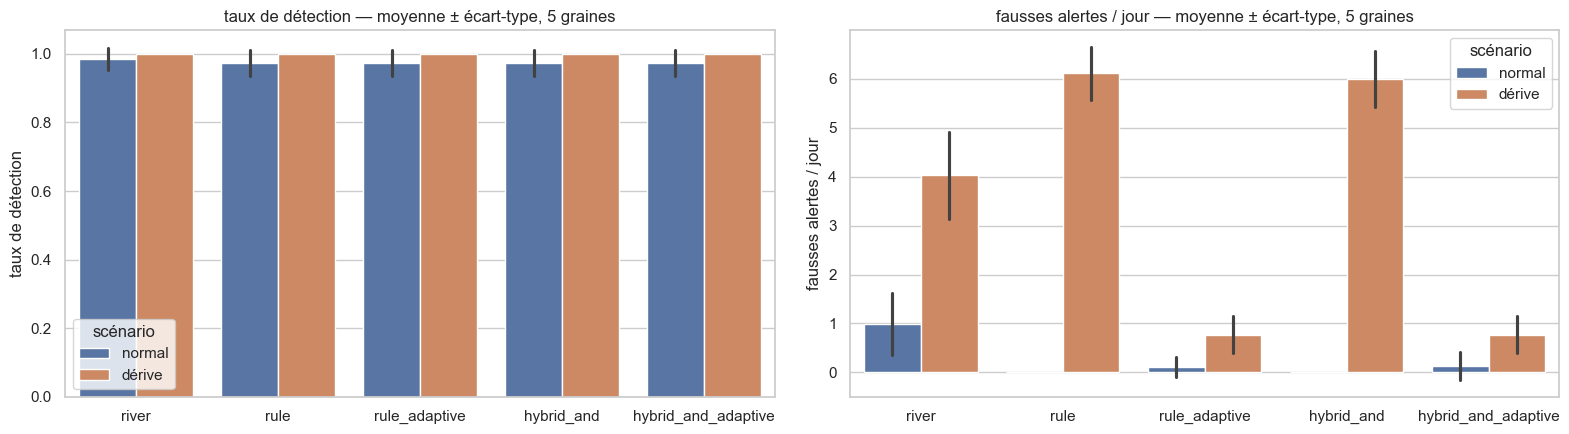


Règle adaptative sous dérive : ≤ 1 fausse alerte/jour et ≥ 90 % de détection → OUI
Mode recommandé (5 graines) : Règle adaptative → 'rule_adaptive' (section 6 bis, 1 graine : 'hybrid_and')


In [26]:
TEST_SEEDS = [SEED + 1, 101, 102, 103, 104]    # 43 = flux de test de la section 6
DRIFT_SEEDS = [SEED + 2, 201, 202, 203, 204]   # 44 = flux de la section 6 bis
MODE_OF = {"River seul": "river", "Règle fixe": "rule", "Règle adaptative": "rule_adaptive",
           "Hybride fixe (règle ET River)": "hybrid_and",
           "Hybride adaptatif (règle adaptative ET River)": "hybrid_and_adaptive"}


def all_alarms(df: pd.DataFrame) -> dict[str, np.ndarray]:
    feats = stream_features(df)
    river_al = alarms(hst_scores(to_unit(feats).to_dict("records"), **PARAMS), THRESHOLD, N_CONSEC_BEST)
    fixed_al = alarms(feats["imbalance"].abs().to_numpy(), RULE_THRESHOLD, N_CONSEC_BEST)
    adapt_al, _ = adaptive_rule(df)
    return {"River seul": river_al, "Règle fixe": fixed_al, "Règle adaptative": adapt_al,
            "Hybride fixe (règle ET River)": fixed_al & river_al,
            "Hybride adaptatif (règle adaptative ET River)": adapt_al & river_al}


t_seeds = time.perf_counter()
rows = []
for scenario, seeds in [("normal", TEST_SEEDS), ("dérive", DRIFT_SEEDS)]:
    for seed in seeds:
        kw = {} if scenario == "normal" else {"drift_day": DRIFT_DAY, "flush_m3h": FLUSH_M3H}
        df = make_stream(days=14, n_leaks=14, seed=seed, **kw)
        lab = df["label"].to_numpy()
        start = WARMUP if scenario == "normal" else DRIFT_START
        n_spikes = int(df["spike"].iloc[start:].sum())
        for method, al in all_alarms(df).items():
            m = evaluate(lab, al, N_CONSEC_BEST, start=start)
            rows.append({"scénario": scenario, "graine": seed, "méthode": method, "pics isolés": n_spikes,
                         "fuites": m["events"], "détectées": m["detected"],
                         "taux de détection": m["detected"] / m["events"] if m["events"] else np.nan,
                         "délai (messages)": m["delay_msgs_mean"],
                         "fausses alertes / jour": m["false_alarms_per_day"], "F1": m["f1"]})
seeds_table = pd.DataFrame(rows)
print(f"{len(TEST_SEEDS) + len(DRIFT_SEEDS)} flux rejoués en {time.perf_counter() - t_seeds:.0f} s")
print("Pics isolés évalués par flux :",
      seeds_table.drop_duplicates(["scénario", "graine"]).groupby("scénario")["pics isolés"].apply(list).to_dict())

METRICS = ["taux de détection", "délai (messages)", "fausses alertes / jour", "F1"]
agg = seeds_table.groupby(["scénario", "méthode"], sort=False)
mean, std = agg[METRICS].mean(), agg[METRICS].std(ddof=1)
totals = agg[["détectées", "fuites"]].sum()
summary = pd.DataFrame(index=mean.index)
summary["fuites détectées (total 5 graines)"] = totals["détectées"].astype(str) + "/" + totals["fuites"].astype(str)
for c in METRICS:
    summary[c] = [f"{a:.2f} ± {b:.2f}" for a, b in zip(mean[c], std[c])]
summary["délai (s réelles)"] = [f"{a * msg_seconds:.2f} ± {b * msg_seconds:.2f}"
                                for a, b in zip(mean["délai (messages)"], std["délai (messages)"])]
print("\nMoyenne ± écart-type sur 5 graines (estimation simulée)")
display(summary)

print("\nFausses alertes / jour, graine par graine")
display(seeds_table.pivot_table(index=["scénario", "graine"], columns="méthode", values="fausses alertes / jour",
                                sort=False).round(2))

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for ax, col in zip(axes, ["taux de détection", "fausses alertes / jour"]):
    sns.barplot(data=seeds_table, x="méthode", y=col, hue="scénario", errorbar="sd", ax=ax,
                palette=["#4c72b0", "#dd8452"])
    ax.set_xticklabels([MODE_OF[t.get_text()] for t in ax.get_xticklabels()])
    ax.set_xlabel("")
    ax.set_title(f"{col} — moyenne ± écart-type, 5 graines")
fig.tight_layout()
mlflow.log_figure(fig, "fig_5_graines.png")
plt.show()

# Mode recommandé : parmi les méthodes qui détectent ≥ 90 % des fuites en moyenne dans les DEUX scénarios,
# celle qui a le moins de fausses alertes sous dérive (puis en temps normal, puis le délai le plus court).
RECOMMENDED_MODE_SINGLE = RECOMMENDED_MODE   # choix de la section 6 bis (1 graine), gardé pour mémoire
ok = [mt for mt in MODE_OF if all(mean.loc[(sc, mt), "taux de détection"] >= 0.9 for sc in ("normal", "dérive"))]
if ok:
    best_method = min(ok, key=lambda mt: (round(mean.loc[("dérive", mt), "fausses alertes / jour"], 2),
                                          round(mean.loc[("normal", mt), "fausses alertes / jour"], 2),
                                          mean.loc[("normal", mt), "délai (messages)"]))
    RECOMMENDED_MODE = MODE_OF[best_method]
else:
    best_method = None
    print("Aucune méthode ne détecte ≥ 90 % des fuites dans les deux scénarios : mode inchangé.")
ADAPTIVE_FIXES_DRIFT = bool(mean.loc[("dérive", "Règle adaptative"), "fausses alertes / jour"] <= 1.0
                            and mean.loc[("dérive", "Règle adaptative"), "taux de détection"] >= 0.9)
print(f"\nRègle adaptative sous dérive : ≤ 1 fausse alerte/jour et ≥ 90 % de détection → "
      f"{'OUI' if ADAPTIVE_FIXES_DRIFT else 'NON'}")
print(f"Mode recommandé (5 graines) : {best_method} → '{RECOMMENDED_MODE}' "
      f"(section 6 bis, 1 graine : '{RECOMMENDED_MODE_SINGLE}')")

MULTI_SEED = {
    "test_seeds": TEST_SEEDS, "drift_seeds": DRIFT_SEEDS,
    "adaptive_rule": {"window_pumping_ticks": ADAPT_WINDOW, "min_history_ticks": ADAPT_MIN,
                      "accept_after_pumping_ticks": ACCEPT_AFTER, "abs_threshold_m3h": RULE_THRESHOLD,
                      "consecutive_ticks": N_CONSEC_BEST},
    "summary": {f"{sc} | {mt}": {**{f"{c}_mean": round(float(mean.loc[(sc, mt), c]), 4) for c in METRICS},
                                 **{f"{c}_std": round(float(std.loc[(sc, mt), c]), 4) for c in METRICS},
                                 "detected": int(totals.loc[(sc, mt), "détectées"]),
                                 "events": int(totals.loc[(sc, mt), "fuites"])}
                for sc, mt in mean.index},
    "adaptive_fixes_drift": ADAPTIVE_FIXES_DRIFT,
    "recommended_mode": RECOMMENDED_MODE,
    "recommended_mode_single_seed": RECOMMENDED_MODE_SINGLE,
}
mlflow.log_metrics({f"seeds_{sc}_{MODE_OF[mt]}_fa_day": float(mean.loc[(sc, mt), "fausses alertes / jour"])
                    for sc, mt in mean.index if sc == "normal"})
mlflow.log_metrics({f"seeds_drift_{MODE_OF[mt]}_fa_day": float(mean.loc[("dérive", mt), "fausses alertes / jour"])
                    for mt in MODE_OF})

## 7. Export de la configuration River

In [27]:
river_config = {
    "model": "river.anomaly.HalfSpaceTrees",
    "river_version": river.__version__,
    "params": {**PARAMS, "seed": SEED},
    "threshold": THRESHOLD,
    "consecutive_ticks": N_CONSEC_BEST,
    "features": FEATURES,
    "feature_definitions": {
        "imbalance": "S1 - (S2 + S3 + S4 + S5), m³/h",
        "s1_resid": "S1 mesuré - S1 du plan, m³/h",
        "s2_resid": "S2 mesuré - plan parcelle A, m³/h",
        "s3_resid": "S3 mesuré - plan parcelle B, m³/h",
        "s4_resid": "S4 mesuré - plan parcelle C, m³/h",
    },
    "feature_scaling": {"formula": "x01 = clip(0.5 + x / (2 * scale_m3h), 0, 1)", "scale_m3h": SCALE_M3H},
    "update": "score_one(x) puis learn_one(x) à chaque message de débit",
    "tick_minutes": TICK_MIN,
    "warmup_ticks": WARMUP,
    "warmup_note": "HalfSpaceTrees ne score qu'après une fenêtre complète : au démarrage, le consumer peut "
                   "préchauffer le modèle en rejouant un flux normal synthétique (aucune alerte pendant le warmup).",
    "calibrated_on": "flux synthétique 14 jours (graine 42), testé sur un flux indépendant (graine 43) — estimation simulée",
    "rule_baseline": {"feature": "imbalance", "abs_threshold_m3h": RULE_THRESHOLD,
                      "consecutive_ticks": N_CONSEC_BEST},
    "adaptive_rule": {
        "description": "|déséquilibre - référence| > abs_threshold_m3h pendant consecutive_ticks messages ; "
                       "référence = médiane des window_pumping_ticks derniers messages de pompage normaux "
                       "(0 si pompe arrêtée ou historique < min_history_ticks) ; messages en écart exclus ; "
                       "écart persistant accept_after_pumping_ticks messages → nouveau normal (bouton)",
        "pumping": "S1_plan > 0.5 m³/h",
        **MULTI_SEED["adaptive_rule"],
    },
    "recommended_mode": RECOMMENDED_MODE,
    "recommended_mode_basis": "évaluation 5 graines × (normal, dérive), section 6 ter",
    "modes": {"river": "alerte River seule", "rule": "alerte règle fixe seule",
              "rule_adaptive": "alerte règle adaptative seule",
              "hybrid_and": "alerte si la règle fixe ET River sont d'accord",
              "hybrid_and_adaptive": "alerte si la règle adaptative ET River sont d'accord"},
}
with open(ARTIFACTS / "river_config.json", "w", encoding="utf-8") as f:
    json.dump(river_config, f, ensure_ascii=False, indent=2)


def _clean(m: dict) -> dict:
    return {k: (None if isinstance(v, float) and not np.isfinite(v) else round(float(v), 4)) for k, v in m.items()}


river_metrics = {
    "model": "River HalfSpaceTrees (river_config.json)",
    "data": "flux synthétique au format du simulateur — estimation simulée",
    "test": _clean(hst_test),
    "test_rule_baseline": _clean(rule_test),
    "delay_seconds_real_mean": (None if not np.isfinite(hst_test["delay_msgs_mean"])
                                else round(hst_test["delay_msgs_mean"] * msg_seconds, 2)),
    "seconds_per_message": round(msg_seconds, 3),
    "val_f1": round(float(BEST["f1"]), 4),
    "test_hybrid_and": _clean(hybrid_test),
    "drift_scenario": {
        "description": f"rinçage des filtres {FLUSH_M3H} m³/h non mesuré par S2-S4 à partir du jour {DRIFT_DAY}",
        "results": {f"{m} | {p}": _clean(drift_table.loc[(m, p)].drop("fuites détectées").to_dict())
                    for m, p in drift_table.index},
        "river_better_than_rule": bool(RIVER_BETTER),
        "recommended_mode_single_seed": RECOMMENDED_MODE_SINGLE,
    },
    "multi_seed": MULTI_SEED,
}
with open(ARTIFACTS / "river_metrics.json", "w", encoding="utf-8") as f:
    json.dump(river_metrics, f, ensure_ascii=False, indent=2)

mlflow.log_params({**PARAMS, "threshold": THRESHOLD, "consecutive_ticks": N_CONSEC_BEST,
                   "tick_minutes": TICK_MIN, "scale_m3h": SCALE_M3H})
mlflow.log_metrics({f"test_{k}": v for k, v in _clean(hst_test).items() if v is not None})
mlflow.log_metrics({f"rule_{k}": v for k, v in _clean(rule_test).items() if v is not None})
for name in ("river_config.json", "river_metrics.json"):
    mlflow.log_artifact(str(ARTIFACTS / name))

# Contrôle : un modèle recréé depuis la config donne les mêmes scores (comme le fera le consumer)
cfg = json.loads((ARTIFACTS / "river_config.json").read_text(encoding="utf-8"))
p = cfg["params"]
rebuilt = anomaly.HalfSpaceTrees(n_trees=p["n_trees"], height=p["height"], window_size=p["window_size"], seed=p["seed"])
check = []
for x in test_records[:600]:
    check.append(rebuilt.score_one(x))
    rebuilt.learn_one(x)
assert np.allclose(check, test_scores[:600])
print("Artefacts écrits : river_config.json, river_metrics.json (config rechargée → scores identiques)")

Artefacts écrits : river_config.json, river_metrics.json (config rechargée → scores identiques)


## Résumé des métriques

In [28]:
print(f"=== 04_river_calibration — exécuté en {time.perf_counter() - T0:.1f} s ===")
print(f"Config retenue : {PARAMS} | seuil {THRESHOLD:.4f} | {N_CONSEC_BEST} messages consécutifs")
print(f"1 message = {TICK_MIN} min simulées = {msg_seconds:.2f} s réelles (SIM_SECONDS_PER_HOUR={SIM_SECONDS_PER_HOUR})")
for name, m in [("HalfSpaceTrees", hst_test), ("Règle |déséquilibre|>0,5", rule_test),
                ("Hybride (règle ET River)", hybrid_test)]:
    print(f"\n{name} — flux de test (estimation simulée)")
    print(f"  précision {m['precision']:.3f} | rappel {m['recall']:.3f} | F1 {m['f1']:.3f}")
    print(f"  fuites détectées : {m['detected']} / {m['events']} ; délai moyen {m['delay_msgs_mean']:.1f} messages"
          f" ≈ {m['delay_msgs_mean'] * msg_seconds:.1f} s réelles ; fausses alertes {m['false_alarms_per_day']:.2f} / jour")
print("\nCritère Phase 5 : alerte en < 10 s réelles ⇒ délai < "
      f"{10 / msg_seconds:.0f} messages (HST : {hst_test['delay_msgs_mean']:.1f})")
print(f"\nScénario de dérive (rinçage {FLUSH_M3H} m³/h dès le jour {DRIFT_DAY}), après la dérive :")
for k in drift_alarms:
    print(f"  {k:28s} F1 {f1[k]:.3f} | fausses alertes {fa[k]:.1f} / jour")
print(f"River meilleur que la règle sous dérive : {'OUI' if RIVER_BETTER else 'NON'} (1 graine)")
print("\n5 graines, moyenne ± écart-type (normal = après préchauffage ; dérive = tout après le rinçage)")
for sc in ("normal", "dérive"):
    for mt in MODE_OF:
        r = summary.loc[(sc, mt)]
        print(f"  {sc:7s} {MODE_OF[mt]:20s} détection {r['taux de détection']} | délai {r['délai (s réelles)']} s "
              f"| fausses alertes/jour {r['fausses alertes / jour']}")
print(f"Mode recommandé (5 graines) : '{RECOMMENDED_MODE}' ; règle adaptative corrige la dérive : "
      f"{'OUI' if ADAPTIVE_FIXES_DRIFT else 'NON'}")
mlflow.end_run()

=== 04_river_calibration — exécuté en 38.8 s ===
Config retenue : {'n_trees': 25, 'height': 10, 'window_size': 288} | seuil 0.3317 | 2 messages consécutifs
1 message = 10 min simulées = 0.83 s réelles (SIM_SECONDS_PER_HOUR=5)

HalfSpaceTrees — flux de test (estimation simulée)
  précision 0.884 | rappel 0.954 | F1 0.918
  fuites détectées : 12 / 12 ; délai moyen 0.7 messages ≈ 0.6 s réelles ; fausses alertes 0.91 / jour

Règle |déséquilibre|>0,5 — flux de test (estimation simulée)
  précision 1.000 | rappel 0.857 | F1 0.923
  fuites détectées : 12 / 12 ; délai moyen 1.0 messages ≈ 0.8 s réelles ; fausses alertes 0.00 / jour

Hybride (règle ET River) — flux de test (estimation simulée)
  précision 1.000 | rappel 0.857 | F1 0.923
  fuites détectées : 12 / 12 ; délai moyen 1.0 messages ≈ 0.8 s réelles ; fausses alertes 0.00 / jour

Critère Phase 5 : alerte en < 10 s réelles ⇒ délai < 12 messages (HST : 0.7)

Scénario de dérive (rinçage 0.6 m³/h dès le jour 7), après la dérive :
  HalfSpac